# Grover's Search with an Imprecise Oracle

**Adapted from the original project by James Saslow:** [Grover's Imprecise Oracle](https://github.com/jamessaslow/grovers-imprecise-oracle)

This notebook studies how an oracle phase error changes the probability of measuring the marked state. It compares a state-vector simulation with Grover's two-dimensional amplitude picture, then estimates the phase-error tolerance as the register size grows.

The notebook has been revised with clearer analysis, interpolated threshold estimates, and additional numerical results.

In [1]:
# Importing packages
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, execute, Aer, transpile
S_simulator = Aer.backends(name='statevector_simulator')[0]

In [ ]:
def GroverIters(num_qubits):
    """Return the usual iteration count for one marked item in 2**num_qubits states."""
    return int(np.pi / 4 * np.sqrt(2**num_qubits))


def EpsFunc(theta, prob, percentage):
    """Interpolate the probability-threshold crossing nearest theta=pi."""
    theta = np.asarray(theta, dtype=float)
    prob = np.asarray(prob, dtype=float)
    if theta.ndim != 1 or prob.ndim != 1 or theta.shape != prob.shape:
        raise ValueError("theta and prob must be one-dimensional arrays of equal length")
    if theta.size < 2 or not np.all(np.isfinite(theta)) or not np.all(np.isfinite(prob)):
        raise ValueError("theta and prob must contain at least two finite samples")
    if not np.isfinite(percentage):
        raise ValueError("percentage must be finite")
    if np.any(np.diff(theta) <= 0):
        raise ValueError("theta values must be strictly increasing")

    difference = prob - percentage
    crossings = list(theta[np.flatnonzero(difference == 0)])
    for index in np.flatnonzero(difference[:-1] * difference[1:] < 0):
        fraction = -difference[index] / (difference[index + 1] - difference[index])
        crossings.append(theta[index] + fraction * (theta[index + 1] - theta[index]))
    if not crossings:
        raise ValueError(f"No probability={percentage} crossing appears in the supplied theta range")
    return float(min(abs(value - np.pi) for value in crossings))


def Grovers(num_qubits, theta, iters=None):
    """Return the marked-state amplitude after Grover iterations with phase theta."""
    if not isinstance(num_qubits, (int, np.integer)) or isinstance(num_qubits, bool) or num_qubits < 1:
        raise ValueError("num_qubits must be a positive integer")

    phases = np.asarray(theta, dtype=float)
    scalar_input = phases.ndim == 0
    if scalar_input:
        phases = phases.reshape(1)
    elif phases.ndim != 1:
        raise ValueError("theta must be a scalar or one-dimensional array")
    if not np.all(np.isfinite(phases)):
        raise ValueError("theta values must be finite")

    iterations = GroverIters(num_qubits) if iters is None else iters
    if not isinstance(iterations, (int, np.integer)) or isinstance(iterations, bool) or iterations < 0:
        raise ValueError("iters must be a non-negative integer")

    num_bases = 2**num_qubits
    initial_amplitude = 1 / np.sqrt(num_bases)
    marked_states = np.empty(phases.size, dtype=complex)
    for index, phase in enumerate(phases):
        marked = initial_amplitude
        unmarked = initial_amplitude
        for _ in range(iterations):
            marked *= np.exp(1j * phase)
            average = (unmarked * (num_bases - 1) + marked) / num_bases
            marked = 2 * average - marked
            unmarked = 2 * average - unmarked
        marked_states[index] = marked

    return marked_states[0] if scalar_input else marked_states


In [ ]:
# Custom Qiskit Function that reiurn the wavefunction psi with basis vectors in ascending binary order

def ReturnPsi(obj, **kwargs):
    '''
    Returns the wavefunction psi in a numpy array
    '''
    if(type(obj) == QuantumCircuit  ):
        statevec = execute( obj, S_simulator, shots=1 ).result().get_statevector()
    if(type(obj) == np.ndarray):
        statevec = obj
    statevec = list( np.asarray(statevec) )
    #==========================================
    dec = 5
    if 'precision' in kwargs:
        dec = int( kwargs['precision'] )
           
    # Rounding off states
    statevec = np.round(statevec,dec) 
    num_bases = len(statevec)
    num_qubits = int(np.log2(num_bases))
    
    
    def bin_gen(number, num_qubits):
        bin1 = bin(number)[2:]
        L = num_qubits - len(bin1)
        bin2 = L*'0' + bin1
        return bin2
    
    def rev_bin_gen(number, num_qubits):
        return bin_gen(number, num_qubits)[::-1]
    
    def binto10(number):
        num_qubits = len(number)
        num_bases  = int(2**num_qubits)
        reg_order = []
        for i in range(num_bases):
            reg_order.append(bin_gen(i, num_qubits))
            
        reg_order = np.array(reg_order)
        return np.where(reg_order == number)[0][0]
    
    def dual_sort(key, values):
        k=1
        while k!=0:
            k=0
            for i in range(len(key)-1):
                a = key[i]
                b = key[i+1]

                c = values[i]
                d = values[i+1]

                if b<a:
                    k+=1
                    key[i] = b
                    key[i+1] = a

                    values[i] = d
                    values[i+1] = c
                       
        return values

    key = []
    for i in range(num_bases):
        key.append(binto10(rev_bin_gen(i, num_qubits)))
        
    psi = dual_sort(key, statevec)
    
    return psi
    
    
# Making a function that converts base 10 to base 2 and uses braket notation
def base10to2(number,num_qubits):
    bin1 = bin(number)[2:]
    L = num_qubits - len(bin1)
    bin2 = L*'0' + bin1
    return '|' + bin2 + '>'
    
    
def HistPsi(qc):
    '''
    Description:
    Plots a histogram of probabilities associated with the wavefunction
    '''
    
    psi = ReturnPsi(qc)
    num_bases = len(psi)
    num_qubits = int(np.log2(num_bases))
    probs = abs(psi)**2
    
    states = []
    for i in range(num_bases):
        states.append( base10to2(i, num_qubits) )
    
    plt.bar(states, probs)
    plt.xticks(rotation = 45)
    plt.xlabel('State')
    plt.ylabel('Probability')
    plt.title('Probability Distribution')
    plt.show()

## 1. Circuit check: quantum circuit and amplitude model

First, build a small Qiskit circuit and compare its marked-state amplitude with the two-amplitude model. The oracle uses phase `theta = pi + epsilon`; the standard Grover oracle is recovered when `epsilon = 0`.

The comparison is about measurement probabilities: amplitudes can differ by a global phase without changing any observable result.


In [4]:
#=======================================================================
# Initializing Quantum Circuit

num_qubits = 3 # Number of Qubits

t_grovers = int(np.pi/4 * np.sqrt(2**num_qubits)) # Number of Grover iterations
print('Number of Grover iters: ', t_grovers)

# Initializing Quantum Circuit
q     = QuantumRegister(num_qubits,name='q')
c     = ClassicalRegister(num_qubits,'c')
qc    = QuantumCircuit(q,c, name = 'qc')

#=======================================================================
# Defining Quantum Gates / Operators


def H_transform():
    for i in range(len(q)):
        qc.h(q[i])   
        
def X_transform():
    for i in range(len(q)):
        qc.x(q[i])
        
# CPhase gate=  oracle call
def CPhase(theta):
    qc.mcp(theta,q[1:len(q)], q[0])
    
# Diffusion Operator
def Us():
    H_transform()
    X_transform()
    CPhase(np.pi)
    X_transform()
    H_transform()
    
def measure():
    for i in range(len(q)):
        qc.measure(q[i],c[i])
    
#=======================================================================
# Constructing Quantum Circuit
psi_list = []

H_transform() # Transforming register into equal superposition state

qc.barrier()

epsilon = 0.5

# Iterating grover's algorithm the optimal number of times
for i in range(t_grovers):
    
    CPhase(np.pi + epsilon) # Applying a control phase gate
    
    qc.barrier()

    Us() # Applying the diffusion operator
    
    psi_list.append(ReturnPsi(qc))

Number of Grover iters:  2


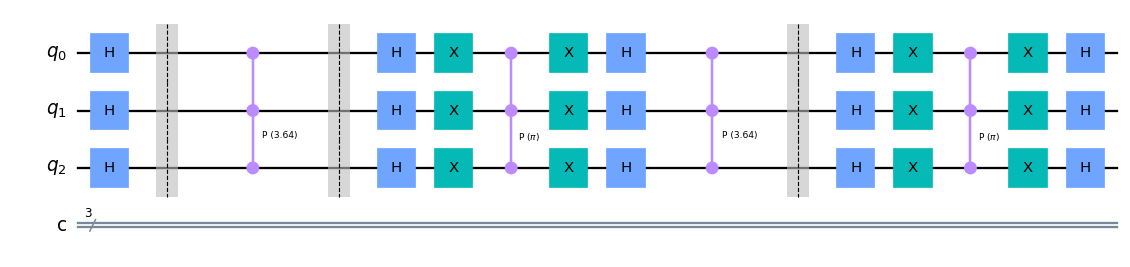

Probability Distribution of Psi after QC


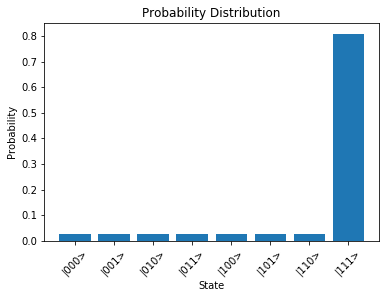

In [5]:
# Drawing Quantum Circuit
fig, ax = plt.subplots(figsize=(int(2*10), int(2*6)))  # Adjust the figsize as needed
qc.draw(output='mpl', ax=ax, scale=1.0)
plt.show()


print('Probability Distribution of Psi after QC')
HistPsi(qc)

# Qiskit Results

In [6]:
psi1 = psi_list[0] # psi after the first iteration
psi2 = psi_list[1] # psi after the second iteration

marked1 = psi1[-1] # Marked state after the first iteration
marked2 = psi2[-1] # Marked State After the second iteration

prob1 = np.abs(psi1)**2
prob2 = np.abs(psi2)**2

print('Quantum Circuit Computation for epsilon = ' + str(epsilon))
print('marked0 = ', 1/np.sqrt(2**num_qubits))
print('marked1 = ', marked1)
print('marked2 = ', marked2)

Quantum Circuit Computation for epsilon = 0.5
marked0 =  0.35355339059327373
marked1 =  (-0.85142-0.12713j)
marked2 =  (0.84298+0.31566j)


# Geometry Results

In [7]:
print('marked0 = ', 1/np.sqrt(2**num_qubits))

for i in range(1,3):
    print('marked'+ str(i)+' = ',Grovers(num_qubits, np.pi + epsilon, iters = i))

marked0 =  0.35355339059327373
marked1 =  (0.8514226512496336+0.12712689353289178j)
marked2 =  (0.8429790422543981+0.3156612264893468j)


Ok! So it seems like we have a match for the results of the marked amplitude between Quantum Circuit and Geormatrical Interpretations. The only apparent discrepancy here is 'marked1' between both results differ by a global phase, but that's ok because the presence of a global phase has no effect on the measurement/results of our wavefunction.

## 2. Phase-error tolerance around the ideal oracle phase

For each probability threshold, `epsilon` is the angular distance from `pi` to the nearest threshold crossing. Linear interpolation between neighboring samples avoids the grid-resolution error of choosing only the closest sampled point.


In [ ]:
theta = np.linspace(0,2*np.pi,5000)

qubit_sizes = [2,4,6,8,10]

for q in qubit_sizes:
    psi = Grovers(q,theta)
    prob = np.abs(psi)**2
    eps50 = EpsFunc(theta,prob, 0.5)

    plt.figure(figsize = (6.5,4.5))
    plt.title('Marked State Probability Curve for n = ' + str(q))
    plt.plot(theta, prob)
    plt.xlabel('theta')
    plt.ylabel('Probability')
    plt.axhline(0.5, c = 'r', linestyle = '--', alpha = 0.5)
    plt.scatter(np.pi-eps50, 0.5, s = 200, marker = 'x', color = 'purple')
    plt.scatter(np.pi+eps50, 0.5, s = 200, marker = 'x', color = 'purple')
    plt.show()

## 3. Threshold tolerance versus register size

The curves below use marked-state probability thresholds of 50%, 65%, and 80%. The phase scan is narrowed around the previous 50% crossing as the qubit count increases, which gives finer resolution near the increasingly narrow peak. A threshold that the peak never reaches is recorded as undefined (NaN).


In [ ]:
num_qubits_arr = np.arange(2, 15)
thresholds = (0.50, 0.65, 0.80)
epsilon_by_threshold = {threshold: np.zeros(num_qubits_arr.size) for threshold in thresholds}
num_theta_samples = 10000

theta = np.linspace(0, 2 * np.pi, num_theta_samples)
for index, num_qubits in enumerate(num_qubits_arr):
    if index:
        previous_epsilon = epsilon_by_threshold[0.50][index - 1]
        theta = np.linspace(np.pi - previous_epsilon, np.pi + previous_epsilon, num_theta_samples)

    probability = np.abs(Grovers(num_qubits, theta))**2
    for threshold in thresholds:
        if np.max(probability) < threshold:
            epsilon_by_threshold[threshold][index] = np.nan
        else:
            epsilon_by_threshold[threshold][index] = EpsFunc(theta, probability, threshold)

    print(f"{num_qubits} qubits complete ({index + 1}/{num_qubits_arr.size})")

eps50_arr = epsilon_by_threshold[0.50]
eps65_arr = epsilon_by_threshold[0.65]
eps80_arr = epsilon_by_threshold[0.80]


In [ ]:
plt.figure(figsize=(10, 6))
plt.title("Oracle phase tolerance by probability threshold")
plt.plot(num_qubits_arr, eps50_arr, marker="o", label="50% probability")
plt.plot(num_qubits_arr, eps65_arr, marker="o", label="65% probability")
plt.plot(num_qubits_arr, eps80_arr, marker="o", label="80% probability")
plt.xlabel("Number of qubits")
plt.ylabel(r"Phase offset $\epsilon$ (radians)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
ln_eps50 = np.log(eps50_arr)
ln_eps65 = np.log(eps65_arr)
ln_eps80 = np.log(eps80_arr)

plt.figure(figsize=(10, 6))
plt.title("Log phase tolerance by probability threshold")
plt.plot(num_qubits_arr, ln_eps50, marker="o", label="50% probability")
plt.plot(num_qubits_arr, ln_eps65, marker="o", label="65% probability")
plt.plot(num_qubits_arr, ln_eps80, marker="o", label="80% probability")
plt.xlabel("Number of qubits")
plt.ylabel(r"Natural log of phase offset, $\ln(\epsilon)$")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
slope, intercept = np.polyfit(num_qubits_arr, ln_eps50, 1)
fit = slope * num_qubits_arr + intercept

plt.figure(figsize=(10, 6))
plt.title("Linear fit for log 50% phase tolerance")
plt.scatter(num_qubits_arr, ln_eps50, label="Measured values")
plt.plot(num_qubits_arr, fit, color="red", linestyle="--", label=f"Linear fit (slope={slope:.3f})")
plt.xlabel("Number of qubits")
plt.ylabel(r"Natural log of phase offset, $\ln(\epsilon_{50})$")
plt.xticks(num_qubits_arr)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Conclusion

Across the simulated qubit counts, the phase offset that preserves a target success probability gets smaller as the register grows. The approximately straight trend in the log plot is consistent with an exponential decrease over this finite range; the fitted slope summarizes these samples and should not be treated as a proof or an experimental guarantee.

The threshold estimates depend on the chosen Grover iteration count and the one-marked-state model. Extending this study to hardware would require accounting for gate noise, calibration error, and the device-specific implementation of the multi-controlled phase gate.